# HW4 — Rolling IC models and signal scores

This experiment uses a 60-market-session return target. For each test year, the preceding five signal years supply training observations and the next year supplies validation observations. A label enters training only after its realized exit date is known.

We search 32 configurations from a 192-configuration grid. The four candidates with the highest individual validation Pearson IC are retained for each year. Their predictions are normalized separately within each signal-date cross-section and averaged to produce the final score.

The final evaluation starts on April 1, 2016. Earlier test years are exploratory. The prepared `features` table contains the signals retained by the data-preparation notebook.

In [11]:
from pathlib import Path
from itertools import product
import gc
import hashlib
import json
import os
import shutil
import time

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "Lectures/modeling/data/hw4_yisu_60_sessions.duckdb").is_file()), None)
if root is None:
    raise FileNotFoundError("Prepared feature database was not found")

data_path = root / "Lectures/modeling/data/hw4_yisu_60_sessions.duckdb"
output_dir = root / "Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions"
output_dir.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(data_path), read_only=True) as db:
    columns = db.execute("DESCRIBE features").fetchdf()["column_name"].tolist()

source_features = [c for c in columns if c.startswith(("PV_", "FUN_", "SECTOR_"))
                   and c != "FUN_available_date"]
model_features = [c.replace(" ", "_") for c in source_features]
required = {"PRICE_symbol", "PRICE_date", "ENTRY_date", "scheduled_exit", "label_end", "target"}
if not required.issubset(columns) or not source_features or len(set(model_features)) != len(model_features):
    raise ValueError("The prepared feature table or model feature names are invalid")

tree_shapes = [(31, 6), (63, 8), (127, 10), (255, 12)]
leaf_sizes = [50, 150, 400, 1000]
l2_values = [0.0, 1.0, 10.0, 50.0]
feature_fractions = [0.70, 0.85, 1.00]

grid = [
    {"num_leaves": leaves, "max_depth": depth, "min_data_in_leaf": leaf,
     "lambda_l2": l2, "feature_fraction": fraction}
    for (leaves, depth), leaf, l2, fraction in product(
        tree_shapes, leaf_sizes, l2_values, feature_fractions
    )
]
rng = np.random.default_rng(202611)
trials = []
for leaves, depth in tree_shapes:
    candidates = [p for p in grid
                  if (p["num_leaves"], p["max_depth"]) == (leaves, depth)]
    trials.extend(candidates[int(i)] for i in rng.choice(
        len(candidates), size=8, replace=False
    ))

run_config = {
    "source_database": str(data_path),
    "source_size": data_path.stat().st_size,
    "source_modified_ns": data_path.stat().st_mtime_ns,
    "source_features": source_features,
    "model_features": model_features,
    "grid_size": len(grid),
    "trials_per_year": len(trials),
    "selected_per_year": 4,
    "trials": trials,
    "lightgbm_version": lgb.__version__,
    "num_threads": 8,
    "max_bin": 127,
    "learning_rate": 0.05,
    "max_rounds": 400,
    "early_stopping_rounds": 30,
    "ic_smoothing": 1.0,
    "winsor_tail": 0.005,
    "normalization": "daily winsorized population z-score",
    "holding_horizon": "60 market sessions",
}
config_path = output_dir / "run_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != run_config:
    raise ValueError("Data or configuration changed; use a new output directory")
config_path.write_text(json.dumps(run_config, indent=2), encoding="utf-8")

def quote(name):
    return '"' + name.replace('"', '""') + '"'

feature_select = ", ".join(
    f"{quote(source)} AS {quote(model)}"
    for source, model in zip(source_features, model_features)
)

print("Features:", len(model_features))
print("Full grid:", len(grid))
print("Trials per year:", len(trials))
display(pd.DataFrame(trials))

Features: 115
Full grid: 192
Trials per year: 32


,num_leaves,max_depth,min_data_in_leaf,lambda_l2,feature_fraction
0,31,6,150,10.0,0.85
1,31,6,50,10.0,0.85
2,31,6,150,10.0,1.00
3,31,6,150,50.0,0.85
4,31,6,400,1.0,0.70
5,31,6,400,10.0,1.00
6,31,6,1000,50.0,0.85
7,31,6,50,50.0,0.85
8,63,8,1000,10.0,0.70
9,63,8,150,10.0,1.00


## 1. Objective and ensemble rule

The training objective minimizes a smoothed negative mean daily cross-sectional Pearson IC. Validation uses the ordinary, unsmoothed IC. Days with a constant target cannot define IC; a day with constant model predictions contributes zero IC rather than disappearing from candidate comparison.

Each selected model produces one raw prediction per stock. Within each signal date, predictions below the 0.5th percentile or above the 99.5th percentile are clipped to those percentile values. The clipped predictions are centered and divided by their cross-sectional population standard deviation. If every prediction on a date is equal, that model contributes zero for that date. The four normalized predictions are averaged with equal weights.

In [12]:
class DailyIC:
    def __init__(self, dates, target):
        self.group, _ = pd.factorize(pd.to_datetime(dates), sort=True)
        self.target = np.asarray(target, dtype="float64")
        self.count = np.bincount(self.group).astype("float64")
        self.centered_target = self.target - (
            np.bincount(self.group, weights=self.target)[self.group]
            / self.count[self.group]
        )
        self.target_std = np.sqrt(
            np.bincount(self.group, weights=self.centered_target**2) / self.count
        )
        self.valid = (self.count >= 3) & (self.target_std > 1e-12)
        self.safe_target_std = np.where(self.valid, self.target_std, 1.0)
        self.valid_days = int(self.valid.sum())
        if not self.valid_days:
            raise ValueError("No dates have a defined cross-sectional IC")

    def components(self, prediction, smoothing=0.0):
        prediction = np.asarray(prediction, dtype="float64")
        if not np.isfinite(prediction).all():
            raise FloatingPointError("Model predictions are not finite")
        centered = prediction - (
            np.bincount(self.group, weights=prediction)[self.group]
            / self.count[self.group]
        )
        variance = np.bincount(self.group, weights=centered**2) / self.count
        std = np.sqrt(variance + smoothing**2)
        safe_std = np.where(std > 1e-12, std, 1.0)
        covariance = np.bincount(
            self.group, weights=self.centered_target * centered
        ) / self.count
        ic = covariance / (self.safe_target_std * safe_std)
        return centered, variance, safe_std, ic

    def mean_ic(self, prediction):
        _, variance, _, ic = self.components(prediction)
        return float(np.where(
            variance[self.valid] > 1e-24, ic[self.valid], 0.0
        ).mean())

    def objective(self, prediction, dataset):
        centered, _, std, ic = self.components(prediction, smoothing=1.0)
        group = self.group
        ic_gradient = (
            self.centered_target
            / (self.count[group] * self.safe_target_std[group] * std[group])
            - ic[group] * centered / (self.count[group] * std[group]**2)
        )
        gradient = (
            -len(self.target) / self.valid_days
            * ic_gradient * self.valid[group]
        )
        return gradient, np.ones_like(gradient)


def normalize_daily(dates, prediction):
    values = np.asarray(prediction, dtype="float64")
    if not np.isfinite(values).all():
        raise FloatingPointError("Model predictions are not finite")
    dates = pd.Series(pd.to_datetime(dates)).reset_index(drop=True)
    if len(dates) != len(values) or dates.isna().any():
        raise ValueError("Dates and predictions do not match")

    bounds = pd.Series(values).groupby(dates).quantile(
        [run_config["winsor_tail"], 1 - run_config["winsor_tail"]]
    ).unstack()
    lower = dates.map(bounds.iloc[:, 0]).to_numpy(dtype="float64")
    upper = dates.map(bounds.iloc[:, 1]).to_numpy(dtype="float64")
    clipped = np.clip(values, lower, upper)

    group, _ = pd.factorize(dates, sort=True)
    count = np.bincount(group)
    mean = np.bincount(group, weights=clipped) / count
    centered = clipped - mean[group]
    std = np.sqrt(np.bincount(group, weights=centered**2) / count)
    return np.divide(
        centered, std[group],
        out=np.zeros_like(centered),
        where=std[group] > 1e-12
    )


def validation_metrics(dates, target, prediction):
    frame = pd.DataFrame({
        "date": pd.to_datetime(dates),
        "target": target,
        "score": prediction,
    })
    rank_target = frame.groupby("date")["target"].rank()
    rank_score = frame.groupby("date")["score"].rank()
    top = frame.sort_values(["date", "score"], ascending=[True, False])
    top = top.groupby("date", sort=False).head(10).groupby("date")["target"].mean()
    universe = frame.groupby("date")["target"].mean()
    return {
        "ic": DailyIC(dates, target).mean_ic(prediction),
        "rank_ic": DailyIC(dates, rank_target.to_numpy()).mean_ic(
            rank_score.to_numpy()
        ),
        "top10_target_mean": float(top.mean()),
        "universe_target_mean": float(universe.mean()),
        "top10_excess": float((top - universe).mean()),
    }


def write_json(path, data):
    pending = path.with_name(path.name + ".pending")
    pending.write_text(json.dumps(data, indent=2), encoding="utf-8")
    os.replace(pending, path)


def check_source():
    stat = data_path.stat()
    if (stat.st_size, stat.st_mtime_ns) != (
        run_config["source_size"], run_config["source_modified_ns"]
    ):
        raise ValueError("The feature database changed after run_config.json was created")

## 2. Rolling training and model selection

The prepared `features` table is the signal universe. Training further requires a finite target whose realized exit date precedes the relevant cutoff. For a test year, five preceding signal years form the training period and the immediately preceding year forms the validation period. The 2016 model becomes active on April 1, after the January–March buffer.

Candidates run sequentially, with eight CPU threads inside each LightGBM fit. Each completed trial writes its parameters, validation metrics, IC history, and a checkpoint. At most the current four leading candidate model files are kept. The final four are saved as independent LightGBM model files; the ensemble is evaluated on validation observations but does not influence which four candidates are chosen.

In [14]:
def read_window(db, start, end, known_before):
    sql = f"""
        SELECT PRICE_date, target, {feature_select}
        FROM features
        WHERE PRICE_date >= ? AND PRICE_date < ?
          AND target IS NOT NULL AND label_end IS NOT NULL
          AND label_end < ? AND isfinite(target)
        ORDER BY PRICE_date
    """
    return db.execute(sql, [start, end, known_before]).fetchdf()


def completed_summary():
    rows = [
        json.loads(p.read_text())["summary"]
        for p in output_dir.glob("20??/selection.json")
    ]
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values("test_year").reset_index(drop=True)


def run_rolls(test_years=range(2007, 2027)):
    check_source()
    with duckdb.connect(str(data_path), read_only=True) as db:
        for year in test_years:
            folder = output_dir / str(year)
            trial_dir = folder / "trials"
            working = folder / "working_models"
            trial_dir.mkdir(parents=True, exist_ok=True)
            working.mkdir(exist_ok=True)
            selection_path = folder / "selection.json"

            if selection_path.exists():
                selection = json.loads(selection_path.read_text())
                if len(selection["selected_models"]) != 4 or any(
                    not (folder / entry["file"]).is_file()
                    for entry in selection["selected_models"]
                ):
                    raise FileNotFoundError(f"Incomplete selected models for {year}")
                print(year, "already completed")
                continue

            # Resume a year from its consecutive, completed trial checkpoints.
            records = []
            for number, trial in enumerate(trials, start=1):
                record_path = trial_dir / f"trial_{number:02d}.json"
                if not record_path.exists():
                    break
                record = json.loads(record_path.read_text())
                if record["trial"] != number or record["parameters"] != trial:
                    raise ValueError(f"Trial checkpoint mismatch for {year}, trial {number}")
                records.append(record)

            if any(
                (trial_dir / f"trial_{n:02d}.json").exists()
                for n in range(len(records) + 2, len(trials) + 1)
            ):
                raise ValueError(f"Nonconsecutive trial checkpoints for {year}")

            keep = {
                r["trial"] for r in sorted(
                    records, key=lambda r: (-r["ic"], r["trial"])
                )[:4]
            }
            for number in keep:
                if not (working / f"trial_{number:02d}.txt").is_file():
                    raise FileNotFoundError(
                        f"Missing top-four checkpoint for {year}, trial {number}"
                    )
            for path in working.glob("trial_*.txt"):
                if int(path.stem.split("_")[-1]) not in keep:
                    path.unlink()
            (folder / "trials.jsonl").write_text(
                "".join(json.dumps(record) + "\n" for record in records),
                encoding="utf-8",
            )

            train_start = "2000-12-13" if year == 2007 else f"{year - 6}-01-01"
            valid_start = f"{year - 1}-01-01"
            valid_end = f"{year}-01-01"
            deploy_date = "2016-04-01" if year == 2016 else valid_end

            train = read_window(db, train_start, valid_start, valid_start)
            valid = read_window(db, valid_start, valid_end, deploy_date)
            if train.empty or valid.empty:
                raise ValueError(f"Empty training or validation set for {year}")

            train_dates = train.pop("PRICE_date").to_numpy()
            valid_dates = valid.pop("PRICE_date").to_numpy()
            y_train = train.pop("target").to_numpy(dtype="float64")
            y_valid = valid.pop("target").to_numpy(dtype="float64")
            n_train, n_valid = len(train), len(valid)

            train_ic = DailyIC(train_dates, y_train)
            valid_ic = DailyIC(valid_dates, y_valid)
            train_set = lgb.Dataset(
                train,
                label=y_train,
                feature_name=model_features,
                params={"max_bin": run_config["max_bin"],
                        "feature_pre_filter": False},
            )
            valid_set = lgb.Dataset(valid, label=y_valid, reference=train_set)
            train_set.construct()
            valid_set.construct()
            del train
            gc.collect()

            for number in range(len(records) + 1, len(trials) + 1):
                trial = trials[number - 1]
                started = time.perf_counter()
                history = {}
                params = {
                    "objective": train_ic.objective,
                    "metric": "None",
                    "learning_rate": run_config["learning_rate"],
                    "num_leaves": trial["num_leaves"],
                    "max_depth": trial["max_depth"],
                    "min_data_in_leaf": trial["min_data_in_leaf"],
                    "lambda_l2": trial["lambda_l2"],
                    "feature_fraction": trial["feature_fraction"],
                    "max_bin": run_config["max_bin"],
                    "feature_pre_filter": False,
                    "force_col_wise": True,
                    "num_threads": run_config["num_threads"],
                    "seed": 202611,
                    "verbosity": -1,
                }
                metric = lambda prediction, dataset: (
                    "daily_ic", valid_ic.mean_ic(prediction), True
                )
                model = lgb.train(
                    params,
                    train_set,
                    num_boost_round=run_config["max_rounds"],
                    valid_sets=[valid_set],
                    valid_names=["valid"],
                    feval=metric,
                    callbacks=[
                        lgb.early_stopping(
                            run_config["early_stopping_rounds"], verbose=False
                        ),
                        lgb.record_evaluation(history),
                    ],
                )
                best_round = int(model.best_iteration or model.current_iteration())
                prediction = model.predict(
                    valid,
                    num_iteration=best_round,
                    num_threads=run_config["num_threads"],
                )
                metrics = validation_metrics(valid_dates, y_valid, prediction)

                candidate_path = working / f"trial_{number:02d}.txt"
                model.save_model(str(candidate_path), num_iteration=best_round)
                record = {
                    "trial": number,
                    "parameters": trial,
                    "best_round": best_round,
                    "elapsed_seconds": round(time.perf_counter() - started, 1),
                    **metrics,
                }
                write_json(
                    trial_dir / f"trial_{number:02d}_ic_history.json",
                    history.get("valid", {}).get("daily_ic", []),
                )
                write_json(trial_dir / f"trial_{number:02d}.json", record)
                records.append(record)
                with (folder / "trials.jsonl").open("a", encoding="utf-8") as log:
                    log.write(json.dumps(record) + "\n")

                keep = {
                    r["trial"] for r in sorted(
                        records, key=lambda r: (-r["ic"], r["trial"])
                    )[:4]
                }
                for path in working.glob("trial_*.txt"):
                    if int(path.stem.split("_")[-1]) not in keep:
                        path.unlink()

                print(
                    year, "trial", number,
                    "IC", round(record["ic"], 5),
                    "rounds", best_round,
                    "seconds", record["elapsed_seconds"],
                )
                del model, prediction
                gc.collect()

            # Save the four best individual candidates.
            winners = sorted(
                records, key=lambda r: (-r["ic"], r["trial"])
            )[:4]
            ensemble = np.zeros(n_valid, dtype="float64")
            selected = []

            for rank, record in enumerate(winners, start=1):
                name = f"model_{rank:02d}.txt"
                source = working / f"trial_{record['trial']:02d}.txt"
                if not source.is_file():
                    raise FileNotFoundError(
                        f"Missing winning trial {record['trial']} for {year}"
                    )
                pending = folder / f"{name}.pending"
                shutil.copy2(source, pending)
                os.replace(pending, folder / name)

                model = lgb.Booster(model_file=str(folder / name))
                if model.feature_name() != model_features:
                    raise ValueError(
                        f"Model features differ for {year}, trial {record['trial']}"
                    )
                prediction = model.predict(
                    valid,
                    num_iteration=record["best_round"],
                    num_threads=run_config["num_threads"],
                    validate_features=True,
                )
                ensemble += normalize_daily(valid_dates, prediction) / 4

                selected.append({
                    "rank": rank,
                    "trial": record["trial"],
                    "file": name,
                    "best_round": record["best_round"],
                    "valid_ic": record["ic"],
                    "parameters": record["parameters"],
                    "sha256": hashlib.sha256(
                        (folder / name).read_bytes()
                    ).hexdigest(),
                })
                del model, prediction

            ensemble_metrics = validation_metrics(valid_dates, y_valid, ensemble)
            summary = {
                "test_year": year,
                "train_start": train_start,
                "train_end_exclusive": valid_start,
                "validation_year": year - 1,
                "model_active_from": deploy_date,
                "train_rows": n_train,
                "valid_rows": n_valid,
                "best_single_valid_ic": winners[0]["ic"],
                "ensemble_valid_ic": ensemble_metrics["ic"],
                "ensemble_valid_rank_ic": ensemble_metrics["rank_ic"],
                "ensemble_top10_target_mean": ensemble_metrics["top10_target_mean"],
                "ensemble_top10_excess": ensemble_metrics["top10_excess"],
                "selected_trials": ",".join(str(r["trial"]) for r in winners),
            }
            write_json(selection_path, {
                "summary": summary,
                "selected_models": selected,
                "selection_metric": "highest individual validation mean daily Pearson IC",
                "ensemble": "daily 0.5% two-tail winsorization, population z-score, equal weights",
                "feature_schema": "../run_config.json",
            })

            for path in working.glob("trial_*.txt"):
                path.unlink()
            working.rmdir()
            completed_summary().to_csv(output_dir / "summary.csv", index=False)
            print(
                year, "selected trials", summary["selected_trials"],
                "ensemble IC", round(summary["ensemble_valid_ic"], 5),
            )

            del valid, train_set, valid_set, train_ic, valid_ic, ensemble
            gc.collect()

    result = completed_summary()
    result.to_csv(output_dir / "summary.csv", index=False)
    return result

## 3. Run and review training

Train rolling models for 2007–2026. A completed year is skipped when rerunning this cell; an interrupted year resumes from its completed trial checkpoints. Compare the highest individual validation IC with the IC of the four-model ensemble. These are validation results, not test-year backtest returns.

/Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/.venv/lib/python3.12/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


2007 trial 1 IC 0.02968 rounds 86 seconds 10.4
2007 trial 2 IC 0.02986 rounds 86 seconds 10.5
2007 trial 3 IC 0.0325 rounds 72 seconds 9.5
2007 trial 4 IC 0.03405 rounds 1 seconds 3.0
2007 trial 5 IC 0.0279 rounds 4 seconds 3.3
2007 trial 6 IC 0.02655 rounds 11 seconds 4.1
2007 trial 7 IC 0.03096 rounds 1 seconds 3.0
2007 trial 8 IC 0.02875 rounds 1 seconds 3.0
2007 trial 9 IC 0.03423 rounds 97 seconds 12.8
2007 trial 10 IC 0.0271 rounds 77 seconds 12.1
2007 trial 11 IC 0.03048 rounds 3 seconds 3.4
2007 trial 12 IC 0.03343 rounds 78 seconds 12.1
2007 trial 13 IC 0.02177 rounds 4 seconds 4.1
2007 trial 14 IC 0.02511 rounds 77 seconds 12.1
2007 trial 15 IC 0.0361 rounds 66 seconds 10.6
2007 trial 16 IC 0.02421 rounds 1 seconds 3.5
2007 trial 17 IC 0.0371 rounds 4 seconds 4.0
2007 trial 18 IC 0.02743 rounds 77 seconds 11.6
2007 trial 19 IC 0.0251 rounds 3 seconds 4.2
2007 trial 20 IC 0.02596 rounds 2 seconds 3.9
2007 trial 21 IC 0.04186 rounds 4 seconds 3.8
2007 trial 22 IC 0.02674 rounds

/Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/.venv/lib/python3.12/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


2008 trial 1 IC 0.07615 rounds 6 seconds 3.2
2008 trial 2 IC 0.07441 rounds 5 seconds 3.1
2008 trial 3 IC 0.07445 rounds 1 seconds 2.9
2008 trial 4 IC 0.08731 rounds 3 seconds 2.9
2008 trial 5 IC 0.084 rounds 5 seconds 3.0
2008 trial 6 IC 0.08751 rounds 70 seconds 9.3
2008 trial 7 IC 0.06996 rounds 44 seconds 6.6
2008 trial 8 IC 0.06749 rounds 28 seconds 5.0
2008 trial 9 IC 0.06017 rounds 35 seconds 6.7
2008 trial 10 IC 0.06618 rounds 51 seconds 8.6
2008 trial 11 IC 0.04671 rounds 38 seconds 6.3
2008 trial 12 IC 0.06023 rounds 35 seconds 6.5
2008 trial 13 IC 0.0654 rounds 3 seconds 3.5
2008 trial 14 IC 0.06749 rounds 49 seconds 8.4
2008 trial 15 IC 0.06686 rounds 5 seconds 3.6
2008 trial 16 IC 0.07471 rounds 2 seconds 3.2
2008 trial 17 IC 0.0439 rounds 136 seconds 18.2
2008 trial 18 IC 0.06753 rounds 4 seconds 3.8
2008 trial 19 IC 0.06109 rounds 4 seconds 4.3
2008 trial 20 IC 0.05751 rounds 1 seconds 3.8
2008 trial 21 IC 0.05447 rounds 4 seconds 4.0
2008 trial 22 IC 0.05905 rounds 4 se

/Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/.venv/lib/python3.12/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


2009 trial 1 IC -0.04306 rounds 1 seconds 3.1
2009 trial 2 IC -0.03775 rounds 1 seconds 3.1
2009 trial 3 IC -0.05557 rounds 6 seconds 3.6
2009 trial 4 IC -0.044 rounds 1 seconds 3.0
2009 trial 5 IC -0.02091 rounds 1 seconds 3.0
2009 trial 6 IC -0.03582 rounds 11 seconds 4.1
2009 trial 7 IC -0.0339 rounds 12 seconds 4.1
2009 trial 8 IC -0.04217 rounds 1 seconds 3.1
2009 trial 9 IC -0.02217 rounds 1 seconds 3.6
2009 trial 10 IC -0.03947 rounds 3 seconds 4.2
2009 trial 11 IC -0.02185 rounds 1 seconds 3.5
2009 trial 12 IC -0.02218 rounds 1 seconds 3.6
2009 trial 13 IC -0.02484 rounds 1 seconds 3.9
2009 trial 14 IC -0.0382 rounds 1 seconds 3.6
2009 trial 15 IC -0.02877 rounds 15 seconds 4.9
2009 trial 16 IC -0.03247 rounds 1 seconds 3.6
2009 trial 17 IC -0.00925 rounds 1 seconds 4.0
2009 trial 18 IC -0.01673 rounds 1 seconds 3.8
2009 trial 19 IC -0.01897 rounds 1 seconds 4.2
2009 trial 20 IC -0.04184 rounds 1 seconds 4.0
2009 trial 21 IC -0.00607 rounds 1 seconds 4.0
2009 trial 22 IC -0.018

... (31 outputs left out)

2025 trial 1 IC 0.04883 rounds 10 seconds 5.7
2025 trial 2 IC 0.04963 rounds 10 seconds 5.6
2025 trial 3 IC 0.05238 rounds 9 seconds 5.9
2025 trial 4 IC 0.04313 rounds 10 seconds 5.7
2025 trial 5 IC 0.04842 rounds 13 seconds 5.7
2025 trial 6 IC 0.05117 rounds 9 seconds 5.9
2025 trial 7 IC 0.04746 rounds 7 seconds 5.3
2025 trial 8 IC 0.0436 rounds 10 seconds 5.6
2025 trial 9 IC 0.06364 rounds 3 seconds 5.1
2025 trial 10 IC 0.04374 rounds 33 seconds 11.1
2025 trial 11 IC 0.04826 rounds 16 seconds 7.0
2025 trial 12 IC 0.06167 rounds 3 seconds 5.2
2025 trial 13 IC 0.05758 rounds 3 seconds 5.5
2025 trial 14 IC 0.04108 rounds 34 seconds 11.2
2025 trial 15 IC 0.03431 rounds 4 seconds 6.0
2025 trial 16 IC 0.04638 rounds 34 seconds 10.3
2025 trial 17 IC 0.04541 rounds 3 seconds 5.9
2025 trial 18 IC 0.06169 rounds 3 seconds 5.7
2025 trial 19 IC 0.05661 rounds 3 seconds 6.5
2025 trial 20 IC 0.03669 rounds 8 seconds 7.2
2025 trial 21 IC 0.04935 rounds 3 seconds 5.9
2025 trial 22 IC 0.06884 rounds 

/Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/.venv/lib/python3.12/site-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


2026 trial 1 IC -0.02307 rounds 3 seconds 4.5
2026 trial 2 IC -0.01452 rounds 3 seconds 4.4
2026 trial 3 IC -0.03013 rounds 52 seconds 11.2
2026 trial 4 IC -0.01986 rounds 3 seconds 4.4
2026 trial 5 IC -0.00403 rounds 1 seconds 4.0
2026 trial 6 IC -0.03184 rounds 42 seconds 9.9
2026 trial 7 IC -0.00804 rounds 3 seconds 4.5
2026 trial 8 IC -0.01283 rounds 3 seconds 4.4
2026 trial 9 IC 0.00982 rounds 6 seconds 5.5
2026 trial 10 IC -0.01229 rounds 1 seconds 5.3
2026 trial 11 IC 0.01276 rounds 3 seconds 4.9
2026 trial 12 IC 0.01175 rounds 1 seconds 4.8
2026 trial 13 IC 0.0151 rounds 6 seconds 5.8
2026 trial 14 IC -0.01376 rounds 1 seconds 5.3
2026 trial 15 IC -0.002 rounds 3 seconds 5.5
2026 trial 16 IC 0.0006 rounds 4 seconds 5.5
2026 trial 17 IC 0.01069 rounds 5 seconds 6.0
2026 trial 18 IC 0.01211 rounds 9 seconds 6.6
2026 trial 19 IC 0.02936 rounds 6 seconds 6.9
2026 trial 20 IC 0.00842 rounds 6 seconds 6.7
2026 trial 21 IC 0.02423 rounds 3 seconds 5.9
2026 trial 22 IC 0.02921 rounds 6

,test_year,train_start,train_end_exclusive,validation_year,model_active_from,train_rows,valid_rows,best_single_valid_ic,ensemble_valid_ic,ensemble_valid_rank_ic,ensemble_top10_target_mean,ensemble_top10_excess,selected_trials
0,2007,2000-12-13,2006-01-01,2006,2007-01-01,1269555,255432,0.05318,0.04865,0.02778,0.11318,0.07974,"32,27,24,25"
1,2008,2002-01-01,2007-01-01,2007,2008-01-01,1377094,272266,0.08751,0.08006,0.05325,0.09927,0.09422,"6,4,5,1"
2,2009,2003-01-01,2008-01-01,2008,2009-01-01,1490281,290691,-0.00287,-0.01105,-0.02351,-0.13650,-0.03732,"25,21,17,29"
3,2010,2004-01-01,2009-01-01,2009,2010-01-01,1605569,296912,0.12820,0.12704,0.00883,0.54862,0.35443,"5,4,8,6"
4,2011,2005-01-01,2010-01-01,2010,2011-01-01,1704300,307871,0.05717,0.04559,0.01402,0.10195,0.04778,"10,14,20,16"
5,2012,2006-01-01,2011-01-01,2011,2012-01-01,1787421,317981,0.08655,0.08750,0.09424,-0.00301,0.01804,"17,21,18,11"
6,2013,2007-01-01,2012-01-01,2012,2013-01-01,1864936,323843,0.02272,0.01690,0.01629,0.04365,0.02164,"32,20,24,31"
7,2014,2008-01-01,2013-01-01,2013,2014-01-01,1929957,335003,0.02623,-0.01566,-0.03718,0.19653,0.12112,"30,29,18,3"
8,2015,2009-01-01,2014-01-01,2014,2015-01-01,1985954,344356,0.01854,0.01210,-0.03049,0.01285,-0.00161,"29,7,25,27"
9,2016,2010-01-01,2015-01-01,2015,2016-04-01,2046660,458992,0.00522,-0.00014,-0.00284,-0.10159,-0.07670,"20,24,28,21"


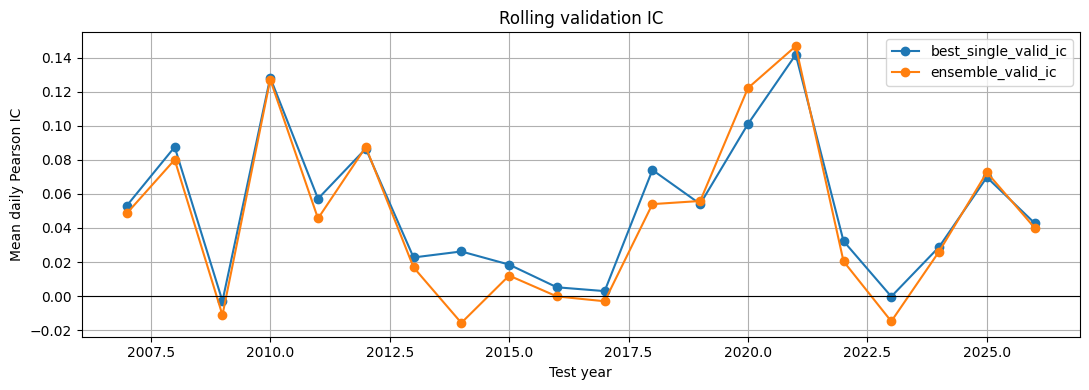

In [15]:
rolling_summary = run_rolls()
display(rolling_summary.round(5))

ax = rolling_summary.plot(
    x="test_year",
    y=["best_single_valid_ic", "ensemble_valid_ic"],
    marker="o",
    figsize=(11, 4),
    grid=True,
    title="Rolling validation IC",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Test year", ylabel="Mean daily Pearson IC")
plt.tight_layout()
plt.show()

## 4. Score the signal universe

After training, load the four selected model files for each test year. Each model scores every eligible stock on every signal date. Clip and standardize each model's predictions within that date, then average the four normalized predictions.

Scoring does not filter on `target` or `label_end`: future outcomes must not decide whether a signal receives a score. Save one Parquet file per year containing stock, signal date, planned entry and exit dates, final score, and model year.

In [16]:
def score_signals(test_years=range(2007, 2027)):
    check_source()
    years = list(test_years)
    missing = [
        year for year in years
        if not (output_dir / str(year) / "selection.json").is_file()
    ]
    if missing:
        raise FileNotFoundError(f"Untrained model years: {missing}")

    summaries = []
    with duckdb.connect(str(data_path), read_only=True) as db:
        for year in years:
            folder = output_dir / str(year)
            selection = json.loads((folder / "selection.json").read_text())
            members = selection["selected_models"]
            if len(members) != 4:
                raise ValueError(f"Expected four models for {year}")

            start = "2016-04-01" if year == 2016 else f"{year}-01-01"
            end = f"{year + 1}-01-01"
            signals = db.execute(f"""
                SELECT PRICE_symbol, PRICE_date, ENTRY_date, scheduled_exit,
                       {feature_select}
                FROM features
                WHERE PRICE_date >= ? AND PRICE_date < ?
                ORDER BY PRICE_date, PRICE_symbol
            """, [start, end]).fetchdf()
            if signals.empty or signals.duplicated(
                ["PRICE_symbol", "PRICE_date"]
            ).any():
                raise ValueError(f"Missing or duplicate signals for {year}")

            combined = np.zeros(len(signals), dtype="float64")
            for member in members:
                model_path = folder / member["file"]
                if (
                    not model_path.is_file()
                    or hashlib.sha256(model_path.read_bytes()).hexdigest()
                    != member["sha256"]
                ):
                    raise ValueError(
                        f"Missing or changed model for {year}, trial {member['trial']}"
                    )
                model = lgb.Booster(model_file=str(model_path))
                if model.feature_name() != model_features:
                    raise ValueError(f"Model feature order differs for {year}")

                prediction = model.predict(
                    signals[model_features],
                    num_iteration=member["best_round"],
                    num_threads=run_config["num_threads"],
                    validate_features=True,
                )
                combined += normalize_daily(
                    signals["PRICE_date"], prediction
                ) / 4
                del model, prediction

            scored = signals[
                ["PRICE_symbol", "PRICE_date", "ENTRY_date", "scheduled_exit"]
            ].copy()
            scored["score"] = combined
            scored["model_year"] = year

            pending = folder / "signal_scores.pending.parquet"
            if pending.exists():
                pending.unlink()
            duckdb.from_df(scored).write_parquet(str(pending))
            os.replace(pending, folder / "signal_scores.parquet")

            summary = {
                "model_year": year,
                "first_signal": scored["PRICE_date"].min().date().isoformat(),
                "last_signal": scored["PRICE_date"].max().date().isoformat(),
                "signals_scored": len(scored),
                "models": 4,
                "selected_trials": selection["summary"]["selected_trials"],
                "model_sha256": [m["sha256"] for m in members],
            }
            write_json(folder / "score_metadata.json", summary)
            summaries.append({
                key: value for key, value in summary.items()
                if key != "model_sha256"
            })
            pd.DataFrame(summaries).to_csv(
                output_dir / "score_summary.csv", index=False
            )
            print(
                year, "signals scored:", len(scored),
                "saved:", folder / "signal_scores.parquet",
            )
            del signals, scored, combined
            gc.collect()

    return pd.DataFrame(summaries)


score_summary = score_signals()
display(score_summary)

2007 signals scored: 362293 saved: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions/2007/signal_scores.parquet
2008 signals scored: 384682 saved: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions/2008/signal_scores.parquet
2009 signals scored: 393324 saved: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions/2009/signal_scores.parquet
2010 signals scored: 407308 saved: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions/2010/signal_scores.parquet
2011 signals scored:

,model_year,first_signal,last_signal,signals_scored,models,selected_trials
0,2007,2007-01-03,2007-12-31,362293,4,"32,27,24,25"
1,2008,2008-01-02,2008-12-31,384682,4,"6,4,5,1"
2,2009,2009-01-02,2009-12-31,393324,4,"25,21,17,29"
3,2010,2010-01-04,2010-12-31,407308,4,"5,4,8,6"
4,2011,2011-01-03,2011-12-30,421273,4,"10,14,20,16"
5,2012,2012-01-03,2012-12-31,429518,4,"17,21,18,11"
6,2013,2013-01-02,2013-12-31,444507,4,"32,20,24,31"
7,2014,2014-01-02,2014-12-31,454445,4,"30,29,18,3"
8,2015,2015-01-02,2015-12-31,459051,4,"29,7,25,27"
9,2016,2016-04-01,2016-12-30,346996,4,"20,24,28,21"
